# TCN e TCN-Attention com e sem pré-processamento/FE × baselines ARIMA, SVR e MLP
**Datasets:** Kaggle *Time Series Forecasting of Solar Energy* (base do artigo do TCN) e INMET 2020 de São Paulo, Florianópolis, Salvador e Fortaleza (base do artigo do professor).

**Referências**
- **[TCN]** Honnurvali et al., *A TCN-Attention Model for High-Accuracy Solar Energy Generation Forecasting*, IEEE OAJPE, v. 13, pp. 690–701, 2026.
- **[MDPI]** de O. Santos Jr. et al., *Solar Irradiance Forecasting Using Dynamic Ensemble Selection*, Appl. Sci. 12, 3510, 2022. Código: github.com/domingos108/solar_forecasting

| Item | Escolha | Fonte |
|---|---|---|
| Split | 60/20/20 cronológico em todos os datasets | [MDPI] Sec. 5, p. 8 |
| Baselines | ARIMA (AutoARIMA stepwise de Hyndman), SVR e MLP com o código do professor reimplementado e a Tabela 1 | [MDPI] Tabela 1, p. 8 |
| TCN e TCN-Attention | Janela: 48 no Kaggle (artigo) e 12 nas cidades (professor); conv. causal dilatada, ReLU, atenção aditiva, saída σ, MSE, Adam | [TCN] Eq. 2–8, Alg. 1, Fig. 6 |
| SEM pré-proc./FE | Série bruta, só Min-Max | — |
| COM pré-proc./FE | Faltantes, IQR, Min-Max, lags, médias móveis, ewm, interação com temperatura, binning, calendário e variáveis meteorológicas | [TCN] Sec. III–IV, Tabela 1, Fig. 2 |
| Métricas | RMSE, MAPE, MAE, ARV e IA na escala [0.1, 0.9] | [MDPI] Sec. 5.2 e Tabela 3 |
| Repetições | 10 execuções independentes | [MDPI] Sec. 5.3, p. 10 |
| Figuras | Boxplot do RMSE, diagrama de distância crítica (Friedman–Nemenyi) e real × TCN-Attention nos 150 primeiros pontos do teste | [MDPI] Figs. 4–12 |

**Retomada:** cada execução é gravada em `resultados/` assim que termina. Se a máquina cair, rode o notebook de novo e ele pula o que já foi feito.
**Sumário**
1. Datasets
2. Métricas
3. Baselines
   - 3.0 Pipeline do professor
   - 3.1 ARIMA
   - 3.2 SVR
   - 3.3 MLP
4. Preparação SEM e COM pré-processamento/FE
5. TCN e TCN-Attention
   - 5.1 Bloco residual causal
   - 5.2 Codificador TCN
   - 5.3 Atenção aditiva
   - 5.4 Modelos completos
   - 5.5 Conferência
   - 5.6 Treino
   - 5.7 Execução
6. Tabelas
7. Boxplot
8. Distância crítica
9. Real × previsto

In [ ]:
# ============ CONFIGURAÇÃO ============
MODO_RAPIDO = False     # True = teste do código (2 execuções, 3 épocas). Para o experimento real: False
N_EXEC = 2 if MODO_RAPIDO else 10
MAX_EPOCAS = 3 if MODO_RAPIDO else 200

# Onde salvar os resultados. No Colab, para não perder nada se a sessão cair, use o Google Drive:
#   from google.colab import drive; drive.mount("/content/drive")
#   PASTA_RESULTADOS = "/content/drive/MyDrive/tcn_fe/resultados"
PASTA_RESULTADOS = "resultados"

In [ ]:
%pip install -q statsforecast
import os, io, zipfile, urllib.request, urllib.parse, copy, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from statsforecast.models import AutoARIMA
from scipy.stats import friedmanchisquare, rankdata
warnings.filterwarnings("ignore")

# Só os DADOS vêm do repositório do professor (arquivos baixados); o código dele está reimplementado abaixo.
URL_DADOS = "https://raw.githubusercontent.com/domingos108/solar_forecasting/main/"
DADOS = Path("dados"); DADOS.mkdir(exist_ok=True)

def baixar(caminho_no_repo):
    destino = DADOS / Path(caminho_no_repo).name
    if not destino.exists():
        urllib.request.urlretrieve(URL_DADOS + urllib.parse.quote(caminho_no_repo), destino)
    return destino

PASTA = Path(PASTA_RESULTADOS); (PASTA / "previsoes").mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", DEVICE, "| execuções:", N_EXEC)

Note: you may need to restart the kernel to use updated packages.
dispositivo: cuda | execuções: 10


## 1. Datasets
- **INMET:** `carregar_horas_solares` reimplementa `tsf.load_data_solar_hours` do professor. Ela pega as horas de 09 a 21 UTC (06 a 18 locais) e preenche faltantes com 0. Dá 4758 amostras = 366 dias × 13 h ([MDPI] Sec. 5.1, p. 9).
- **Kaggle:** `solarenergy.csv`. Usamos as 2920 horas em que todas as variáveis meteorológicas existem ([TCN] Sec. IV.D, p. 698).
- **Variáveis exógenas:** temperatura, umidade, pressão, vento e chuva. Só a condição COM FE usa.

In [ ]:
def carregar_horas_solares(caminho, hora_min="0900 UTC", hora_max="2100 UTC"):
    # = tsf.load_data_solar_hours: lê o CSV do INMET, troca radiação faltante por 0 e mantém de 09 a 21 UTC
    df = pd.read_csv(caminho, sep=";", decimal=",", encoding="utf8")
    df["RADIACAO GLOBAL (Kj/m)"] = df["RADIACAO GLOBAL (Kj/m)"].fillna(0)
    df["Data"] = pd.to_datetime(df["Data"] + " " + df["Hora UTC"], format="%d/%m/%Y %H%M UTC")
    hora = lambda x: int(x.split(" ")[0])                       # = tsf.utc_hour_to_int ("0900 UTC" → 900)
    manter = df["Hora UTC"].apply(lambda x: hora(hora_min) <= hora(x) <= hora(hora_max))
    df = df[manter][["Data", "RADIACAO GLOBAL (Kj/m)"]].rename(columns={"RADIACAO GLOBAL (Kj/m)": "actual"})
    return df.set_index("Data")

INMET = {  # nome: arquivo de dados no repositório do professor
    "Sao Paulo":     "INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2020_A_31-12-2020.csv",
    "Florianopolis": "INMET_S_SC_A806_FLORIANOPOLIS_01-01-2020_A_31-12-2020.csv",
    "Salvador":      "INMET_NE_BA_A401_SALVADOR_01-01-2020_A_31-12-2020.csv",
    "Fortaleza":     "INMET_NE_CE_A305_FORTALEZA_01-01-2020_A_31-12-2020.csv",
}
PREFIXOS = {"temp": "TEMPERATURA DO AR - BULBO SECO", "umid": "UMIDADE RELATIVA DO AR",
            "pres": "PRESSAO ATMOSFERICA AO NIVEL", "vento": "VENTO, VELOCIDADE", "chuva": "PRECIPITACAO TOTAL"}

def carregar_inmet(arquivo):
    caminho = baixar("data/" + arquivo)
    serie = carregar_horas_solares(caminho)                                # = tsf.load_data_solar_hours
    bruto = pd.read_csv(caminho, sep=";", decimal=",")
    bruto.index = pd.to_datetime(bruto["Data"] + " " + bruto["Hora UTC"], format="%d/%m/%Y %H%M UTC")
    exo = pd.DataFrame({k: pd.to_numeric(bruto[[c for c in bruto.columns if c.startswith(p)][0]], errors="coerce").to_numpy()
                        for k, p in PREFIXOS.items()}, index=bruto.index)
    exo = exo.where(exo > -9000).reindex(serie.index)
    return serie[["actual"]], exo

def carregar_kaggle():
    url = "https://www.kaggle.com/api/v1/datasets/download/chaitanyakumar12/time-series-forecasting-of-solar-energy"
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
        df = pd.read_csv(z.open("solarenergy.csv"), low_memory=False)
    df["Datetime"] = pd.to_datetime(df["Datetime"], format="%d/%m/%Y %H:%M")
    df = df.sort_values("Datetime").drop_duplicates("Datetime").set_index("Datetime").asfreq("h")
    df = df.loc[df["temperature"].first_valid_index():]                      # 2920 h com meteorologia
    exo = df[["temperature", "humidity", "average-pressure-(period)", "wind-speed", "average-wind-speed-(period)"]]
    exo.columns = ["temp", "umid", "pres", "vento", "vento_medio"]
    serie = df[["solar_mw"]].rename(columns={"solar_mw": "actual"}).interpolate().ffill()
    return serie, exo

DATASETS = {"Kaggle": dict(zip(["serie", "exo"], carregar_kaggle()), por_dia=24, inmet=False, lookback=48)}
for nome, arquivo in INMET.items():
    DATASETS[nome] = dict(zip(["serie", "exo"], carregar_inmet(arquivo)), por_dia=13, inmet=True, lookback=12)

for nome, d in DATASETS.items():
    n = len(d["serie"]); d["n_te"] = d["n_va"] = int(0.2 * n); d["n_tr"] = n - 2 * d["n_te"]      # 60/20/20
    y = d["serie"]["actual"]
    print(f"{nome:14s} n={n:5d} | treino {d['n_tr']} / val {d['n_va']} / teste {d['n_te']} | "
          f"média {y.mean():8.1f} | DP {y.std():8.1f} | {d['serie'].index[0]} → {d['serie'].index[-1]}")
print("\nConferência [MDPI] Tabela 2 (média/DP): Florianópolis 1230.7/1101.2 | Fortaleza 1223.9/883.18 | "
      "Salvador 1348.2/1122.6 | São Paulo 1355.4/1204.6")

Kaggle         n= 2920 | treino 1752 / val 584 / teste 584 | média  11410.0 | DP   2518.5 | 2020-04-03 09:00:00 → 2020-08-03 00:00:00
Sao Paulo      n= 4758 | treino 2856 / val 951 / teste 951 | média   1355.4 | DP   1204.6 | 2020-01-01 09:00:00 → 2020-12-31 21:00:00
Florianopolis  n= 4758 | treino 2856 / val 951 / teste 951 | média   1230.7 | DP   1101.2 | 2020-01-01 09:00:00 → 2020-12-31 21:00:00
Salvador       n= 4758 | treino 2856 / val 951 / teste 951 | média   1348.2 | DP   1122.6 | 2020-01-01 09:00:00 → 2020-12-31 21:00:00
Fortaleza      n= 4758 | treino 2856 / val 951 / teste 951 | média   1223.9 | DP    883.2 | 2020-01-01 09:00:00 → 2020-12-31 21:00:00

Conferência [MDPI] Tabela 2 (média/DP): Florianópolis 1230.7/1101.2 | Fortaleza 1223.9/883.18 | Salvador 1348.2/1122.6 | São Paulo 1355.4/1204.6


## 2. Métricas (as do professor, na escala do artigo dele)
`metricas_professor` reimplementa `tsf.gerenerate_metric_results`, com as mesmas fórmulas:

| Métrica | Fórmula |
|---|---|
| RMSE | $\sqrt{\frac{1}{N}\sum (y_t-\hat y_t)^2}$ |
| MAPE | $\frac{100}{N}\sum \left|\frac{y_t-\hat y_t}{y_t}\right|$, descartando $y_t = 0$, como no código do professor |
| MAE | $\frac{1}{N}\sum \lvert y_t-\hat y_t\rvert$ |
| ARV | $\frac{\sum (y_t-\hat y_t)^2}{\sum (\hat y_t-\bar y)^2}$ |
| IA | $1-\frac{\sum (y_t-\hat y_t)^2}{\sum (\lvert\hat y_t-\bar y\rvert+\lvert y_t-\bar y\rvert)^2}$ |

**Escala:** antes do cálculo, real e previsto são levados para **[0.1, 0.9], com o mínimo e o máximo da série inteira** ([MDPI] Sec. 5, p. 8). É a convenção da Tabela 3 ([MDPI] p. 11) e só muda a escala do erro; o modelo não vê nada disso.

In [ ]:
def metricas_professor(y_true, y_pred):
    # = tsf.gerenerate_metric_results (RMSE, MAPE, MAE, ARV, IA), com as mesmas fórmulas do código
    y_true, y_pred = np.asarray(y_true, float).ravel(), np.asarray(y_pred, float).ravel()
    erro = y_true - y_pred
    media = y_true.mean()
    nz = y_true != 0                                             # o MAPE do professor descarta os zeros
    return {"RMSE": np.sqrt(np.mean(erro ** 2)),
            "MAPE": np.mean(np.abs(erro[nz] / y_true[nz])) * 100,
            "MAE": np.mean(np.abs(erro)),
            "ARV": np.sum(erro ** 2) / np.sum((y_pred - media) ** 2),
            "IA": 1 - np.sum(erro ** 2) / np.sum((np.abs(y_pred - media) + np.abs(y_true - media)) ** 2)}

METRICAS = ["RMSE", "MAPE", "MAE", "ARV", "IA"]

def metricas(nome, y_true, y_pred):
    y = DATASETS[nome]["serie"]["actual"].to_numpy()
    mn, mx = y.min(), y.max()
    esc = lambda a: 0.1 + 0.8 * (np.asarray(a, float) - mn) / (mx - mn)
    r = metricas_professor(esc(y_true), esc(y_pred))
    return {k: float(r[k]) for k in METRICAS}

In [ ]:
# Registro incremental: cada execução vai para resultados/metricas.csv e resultados/previsoes/*.npy
ARQ = PASTA / "metricas.csv"
RES = pd.read_csv(ARQ) if ARQ.exists() else pd.DataFrame(columns=["dataset", "modelo", "condicao", "execucao"] + METRICAS)

def feitas(nome, modelo, condicao):
    f = RES[(RES.dataset == nome) & (RES.modelo == modelo) & (RES.condicao == condicao)]
    return set(f.execucao.astype(int))

def registrar(nome, modelo, condicao, execucao, pred):
    global RES
    d = DATASETS[nome]; y = d["serie"]["actual"].to_numpy()
    pred = np.clip(np.asarray(pred, float), 0, None)
    assert len(pred) == d["n_te"], f"{modelo}: previsão com {len(pred)} pontos, esperado {d['n_te']}"
    np.save(PASTA / "previsoes" / f"{nome}__{modelo}__{condicao}__{execucao}.npy", pred)
    RES = pd.concat([RES, pd.DataFrame([{"dataset": nome, "modelo": modelo, "condicao": condicao,
                                         "execucao": execucao, **metricas(nome, y[-d["n_te"]:], pred)}])], ignore_index=True)
    RES.to_csv(ARQ, index=False)

## 3. Baselines: ARIMA, SVR e MLP (sempre SEM pré-processamento/FE, como no [MDPI])
O professor também não implementa os modelos do zero.
- **ARIMA:** ele usa o `auto.arima` do pacote `forecast`, em R. Aqui usamos o `AutoARIMA` do `statsforecast`, que é o mesmo método *stepwise* de Hyndman-Khandakar ([MDPI] ref. [65]).
- **SVR e MLP:** ele usa `sklearn.svm.SVR` e `sklearn.neural_network.MLPRegressor`, e aqui também. O que é dele, e está reimplementado abaixo, é o **pipeline em volta**: normalização, janelamento, busca em grade na validação e previsão no teste.

| Modelo | Seção | Implementação | Hiperparâmetros ([MDPI] Tabela 1, p. 8) | Determinístico? |
|---|---|---|---|---|
| ARIMA | 3.1 | `statsforecast.AutoARIMA` | ordem (p, d, q) escolhida pelo *stepwise* no treino | sim: 10 execuções iguais |
| SVR | 3.2 | `sklearn.svm.SVR` + pipeline do professor (3.0) | RBF; C ∈ {10, 100, 1000}; γ ∈ {0.1, 0.01, 0.001}; ε ∈ {0.1, 0.01, 0.001} | sim: 10 execuções iguais |
| MLP | 3.3 | `sklearn.neural_network.MLPRegressor` + pipeline do professor (3.0) | 1 camada oculta sigmoide, L-BFGS; {20, 50, 100} neurônios; tol ∈ {1e-3, 1e-4, 1e-5} | não: pesos iniciais mudam |

Que ARIMA e SVR repetem o mesmo resultado nas 10 execuções está no [MDPI] Sec. 5.4, p. 14.

### 3.0 Pipeline do professor (usado pelo SVR e pela MLP)
Reimplementação de `src/time_series_functions.py` (`tsf`) e `src/fit_predict_models.py` (`fpm`) do repositório github.com/domingos108/solar_forecasting. Cobre o caso do artigo dele: horizonte 1, sem exógenas, com normalização. Cada função indica a original que reproduz. As previsões foram comparadas com as do código original e são idênticas.

Fluxo de `modelo_unico` (= `fpm.single_model`):
1. Min-Max ajustado em treino + validação.
2. Janelas de 12 lags: `lag_12 … lag_1` → `actual`, o 13º valor.
3. `fit` nas janelas de treino e `predict` em todas.
4. Volta à escala original.

`busca_em_grade` (= `fpm.do_grid_search`) testa cada configuração da grade e escolhe a de menor RMSE médio na **validação**. `rodar_baseline` faz a busca uma vez e depois as 10 execuções no teste.

In [ ]:
def criar_janelas(serie, lags):
    # = tsf.create_windowing + fpm.get_windowing: colunas lag_12 … lag_1 e 'actual' (o alvo é o 13º valor)
    s = pd.Series(serie)
    colunas = {f"lag_{i}": s.shift(i) for i in range(lags, 0, -1)}
    return pd.concat([pd.DataFrame(colunas), s.rename("actual")], axis=1).dropna()

def modelo_unico(serie, modelo, lags, n_te, n_va):
    # = fpm.single_model (horizonte 1, sem exógenas, normalize=True)
    y = serie["actual"].to_numpy(float)
    escala = MinMaxScaler().fit(y[:len(y) - n_te].reshape(-1, 1))     # ajustado em treino + validação, como no original
    z = escala.transform(y.reshape(-1, 1)).ravel()
    jan = criar_janelas(z, lags)
    n_ajuste = len(jan) - n_te - n_va                                   # = tsf.fit_sklearn_model
    X, alvo = jan.drop(columns="actual").to_numpy(), jan["actual"].to_numpy()
    modelo.fit(X[:n_ajuste], alvo[:n_ajuste])
    pred = escala.inverse_transform(modelo.predict(X).reshape(-1, 1)).ravel()   # = tsf.predict_sklearn_model
    return pred, y[-len(pred):], n_ajuste                               # previsões de todas as janelas (treino+val+teste)

def busca_em_grade(serie, modelo_base, grade, n_te, n_va, execs):
    # = fpm.do_grid_search: menor RMSE médio na VALIDAÇÃO (escala original), média de `execs` execuções por configuração
    melhor, melhor_rmse, melhor_lags = None, None, None
    for params in ParameterGrid(grade):
        params = dict(params); lags = params.pop("time_window")
        candidato = clone(modelo_base).set_params(**params)
        rmses = []
        for _ in range(execs):
            pred, real, n_ajuste = modelo_unico(serie, candidato, lags, n_te, n_va)
            val = slice(n_ajuste, len(pred) - n_te)
            rmses.append(metricas_professor(real[val], pred[val])["RMSE"])
        if melhor_rmse is None or np.mean(rmses) < melhor_rmse:
            melhor, melhor_rmse, melhor_lags = candidato, np.mean(rmses), lags
    return melhor, melhor_lags

def rodar_baseline(nome, rotulo, modelo_base, parametros, execs_grid, deterministico):
    # Busca em grade na validação e depois N_EXEC execuções no teste, cada uma gravada em resultados/
    if len(feitas(nome, rotulo, "SEM")) >= N_EXEC: return
    d = DATASETS[nome]
    np.random.seed(0)
    melhor, janela = busca_em_grade(d["serie"], modelo_base, parametros, d["n_te"], d["n_va"], execs_grid)
    pred0 = None
    for e in range(N_EXEC):
        if e in feitas(nome, rotulo, "SEM"): continue
        if deterministico and pred0 is not None:
            registrar(nome, rotulo, "SEM", e, pred0); continue
        np.random.seed(e)                                   # MLP: pesos iniciais diferentes a cada execução
        pred = modelo_unico(d["serie"], melhor, janela, d["n_te"], d["n_va"])[0][-d["n_te"]:]
        pred0 = pred
        registrar(nome, rotulo, "SEM", e, pred)
    escolhidos = {k: v for k, v in melhor.get_params().items() if k in parametros}
    print(f"{nome:14s} {rotulo}: {escolhidos} → RMSE médio {RES[(RES.dataset == nome) & (RES.modelo == rotulo)].RMSE.mean():.4f}")

### 3.1 ARIMA ([MDPI] Sec. 3.1, p. 4)
$$\phi(B)\,(1-B)^d\,y_t = c + \theta(B)\,\varepsilon_t,\qquad \phi(B)=1-\textstyle\sum_{i=1}^{p}\phi_i B^i,\quad \theta(B)=1+\textstyle\sum_{j=1}^{q}\theta_j B^j$$

1. **Ordem:** o *stepwise* de Hyndman-Khandakar escolhe (p, d, q) pelo AICc, só no treino.
2. **Teste:** os parâmetros ficam fixos, e a previsão de cada ponto usa as observações reais até t−1 (1 passo à frente). É o mesmo que o `Arima(..., model=ajuste)` do R faz.

In [ ]:
def prever_arima(d):
    # Ajusta o AutoARIMA no treino e devolve as previsões de 1 passo no teste e a ordem (p, d, q) escolhida
    y = d["serie"]["actual"].to_numpy(float)
    modelo = AutoARIMA(season_length=1).fit(y[:d["n_tr"]])
    pred = modelo.forward(y=y, h=1, fitted=True)["fitted"][-d["n_te"]:]     # 1 passo à frente, parâmetros fixos
    p, q, _, _, _, dd, _ = modelo.model_["arma"]
    return pred, (p, dd, q)

for nome, d in DATASETS.items():
    if len(feitas(nome, "ARIMA", "SEM")) >= N_EXEC: continue
    pred, ordem_arima = prever_arima(d)
    for e in range(N_EXEC):                                                # determinístico: as 10 execuções são iguais
        registrar(nome, "ARIMA", "SEM", e, pred)
    print(f"{nome:14s} ARIMA{ordem_arima} | RMSE = {RES[(RES.dataset == nome) & (RES.modelo == 'ARIMA')].RMSE.iloc[0]:.4f}")

### 3.2 SVR ([MDPI] Sec. 3.4, p. 5)
$$\hat y(\mathbf x)=\sum_i(\alpha_i-\alpha_i^*)\,K(\mathbf x_i,\mathbf x)+b,\qquad K(\mathbf x_i,\mathbf x)=\exp\!\left(-\gamma\,\lVert\mathbf x_i-\mathbf x\rVert^2\right)$$

- **Ajuste:** minimiza a perda ε-insensível, em que erros menores que ε não contam, com penalidade C.
- **Entrada:** $\mathbf x$ são os 12 lags; a saída é o 13º valor.
- **Grade:** 3 × 3 × 3 = 27 configurações.
- **Busca:** 1 execução por configuração (`execs_grid=1`), porque o SVR é determinístico.

In [ ]:
# Grade da Tabela 1 do [MDPI], exatamente como no notebook single_model_svr do professor
PARAM_SVR = {"C": [10, 100, 1000], "gamma": [0.1, 0.01, 0.001], "kernel": ["rbf"],
             "epsilon": [0.1, 0.01, 0.001], "tol": [0.001], "time_window": [12]}
SVR_BASE = SVR(max_iter=10000)

for nome in DATASETS:
    rodar_baseline(nome, "SVR", SVR_BASE, PARAM_SVR, execs_grid=1, deterministico=True)

### 3.3 MLP ([MDPI] Sec. 3.5, p. 6)
$$\hat y(\mathbf x)=\mathbf w_2^\top\,\sigma(\mathbf W_1\mathbf x+\mathbf b_1)+b_2,\qquad \sigma(z)=\frac{1}{1+e^{-z}}$$

- **Arquitetura:** uma camada oculta sigmoide, saída linear.
- **Treino:** L-BFGS, até 1000 iterações.
- **Grade:** 3 tamanhos × 3 tolerâncias = 9 configurações.
- **Busca:** cada configuração é avaliada pela média de 10 execuções (`execs_grid=N_EXEC`), como no professor.
- **Execuções:** as 10 execuções finais mudam só os pesos iniciais (semente `e`).

In [ ]:
# Grade da Tabela 1 do [MDPI], exatamente como no notebook single_model_mlp do professor
PARAM_MLP = {"hidden_layer_sizes": [20, 50, 100], "max_iter": [1000],
             "tol": [0.001, 0.0001, 0.00001], "time_window": [12]}
MLP_BASE = MLPRegressor(activation="logistic", solver="lbfgs")

for nome in DATASETS:
    rodar_baseline(nome, "MLP", MLP_BASE, PARAM_MLP, execs_grid=N_EXEC, deterministico=False)

## 4. Preparação para as TCNs: SEM e COM pré-processamento/FE
- **SEM:** a série bruta, igual à dos baselines, só com Min-Max [0, 1] ajustado no treino. Entra 1 variável por passo de tempo.
- **COM:** o pipeline do [TCN].
  - Faltantes: no INMET, um zero entre 11 e 19 UTC é falha de sensor (o professor faz `fillna(0)`). No treino é interpolado; em validação e teste usa forward-fill, que é causal (Sec. III.A, p. 694).
  - IQR com limites do treino, aplicado na série e nas exógenas. Os pontos fora são cortados nos limites (Abstract; Sec. III.A).
  - Lags 1, 2, 3, 4, 1 dia, 2 dias e 7 dias (Fig. 2). No Kaggle, 1 dia = 24 h; no INMET, 13 amostras.
  - Média, máximo e mínimo móveis de 1 dia, e ewm de meio dia e 1 dia (Fig. 2; Sec. IV.A).
  - Interação série × temperatura (`solar_temp_interaction`, Fig. 2).
  - Binning de intensidade em 5 categorias, Very Low … Very High (Sec. IV.D, p. 698).
  - Hora, dia da semana e mês em one-hot (Tabela 1, p. 694).
  - Variáveis meteorológicas.
  - Min-Max [0, 1] em tudo.
- **Janelas:** as L linhas anteriores ao instante previsto. Cada atributo da linha s usa só dados até s, então não há vazamento.
  - **Kaggle:** L = 48, o lookback do artigo do TCN (Sec. IV.F, p. 699).
  - **Cidades do INMET:** L = 12, a mesma janela dos baselines e do professor: 12 lags + o 13º como alvo = 1 dia de 13 horas ([MDPI] Sec. 5.1, p. 9).
- **Teste:** é exatamente o mesmo dos baselines, as últimas `n_te` amostras.

In [ ]:
# Janela de entrada das TCNs por dataset: Kaggle 48 (artigo do TCN); cidades 12 (professor). Ver DATASETS[...]['lookback'].

def preparar(nome, condicao):
    d = DATASETS[nome]; n_tr, D, L = d["n_tr"], d["por_dia"], d["lookback"]
    s = d["serie"]["actual"].astype(float).copy()
    if condicao == "SEM":
        tab = s.to_frame("actual")
    else:
        if d["inmet"]:                                            # zeros com sol alto = faltante (fillna(0) do professor)
            s[(s == 0) & s.index.hour.isin(range(11, 20))] = np.nan
        s = pd.concat([s.iloc[:n_tr].interpolate().ffill().bfill(), s.ffill().iloc[n_tr:]])
        exo = d["exo"].copy()
        exo = pd.concat([exo.iloc[:n_tr].interpolate().ffill().bfill(), exo.ffill().iloc[n_tr:]]).bfill()
        tab = pd.concat([s.rename("actual"), exo], axis=1)
        for c in tab.columns:                                     # IQR (limites do treino) → corte nos limites
            q1, q3 = tab[c].iloc[:n_tr].quantile([0.25, 0.75])
            tab[c] = tab[c].clip(q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
        a = tab["actual"]
        for k in [1, 2, 3, 4, D, 2 * D, 7 * D]:
            tab[f"lag_{k}"] = a.shift(k)
        tab["rolling_mean_dia"] = a.rolling(D).mean()
        tab["rolling_max_dia"] = a.rolling(D).max()
        tab["rolling_min_dia"] = a.rolling(D).min()
        tab["ewm_meio_dia"] = a.ewm(span=max(2, D // 2), adjust=False).mean()
        tab["ewm_dia"] = a.ewm(span=D, adjust=False).mean()
        tab["interacao_temp"] = a * tab["temp"]
        faixa = np.digitize(a, a.iloc[:n_tr].quantile([0.2, 0.4, 0.6, 0.8]).to_numpy())
        for i, rot in enumerate(["very_low", "low", "medium", "high", "very_high"]):
            tab[f"intensidade_{rot}"] = (faixa == i).astype(float)
        cal = pd.DataFrame({"hora": tab.index.hour, "dia_semana": tab.index.day_of_week, "mes": tab.index.month},
                           index=tab.index).astype(str)
        tab = pd.concat([tab, pd.get_dummies(cal, dtype=float)], axis=1)
    continuas = [c for c in tab.columns if tab[c].nunique() > 2]
    esc_x = MinMaxScaler().fit(tab[continuas].iloc[:n_tr])
    tab[continuas] = esc_x.transform(tab[continuas])
    esc_y = MinMaxScaler().fit(s.iloc[:n_tr].to_frame())          # para voltar a previsão à escala original
    M = tab.to_numpy(np.float32)
    z = esc_y.transform(s.to_frame()).ravel().astype(np.float32)
    ok = ~np.isnan(M).any(axis=1)
    inicio = int(np.argmax(ok)) + L                               # 1º alvo com L linhas completas antes
    def jan(a, b):
        idx = range(max(a, inicio), b)
        return (torch.tensor(np.stack([M[t - L:t] for t in idx])), torch.tensor(z[list(idx)]))
    n = len(s)
    return dict(treino=jan(0, n_tr), val=jan(n_tr, n_tr + d["n_va"]), teste=jan(n - d["n_te"], n),
                n_var=M.shape[1], inv=lambda p: esc_y.inverse_transform(np.asarray(p).reshape(-1, 1)).ravel())

DADOS_TCN = {(nome, c): preparar(nome, c) for nome in DATASETS for c in ["SEM", "COM"]}
for (nome, c), dd in DADOS_TCN.items():
    print(f"{nome:14s} {c}: janela {DATASETS[nome]['lookback']} × {dd['n_var']:3d} variáveis | treino {len(dd['treino'][1])} | val {len(dd['val'][1])} | teste {len(dd['teste'][1])}")

Kaggle         SEM: janela 48 ×   1 variáveis | treino 1704 | val 584 | teste 584
Kaggle         COM: janela 48 ×  60 variáveis | treino 1536 | val 584 | teste 584
Sao Paulo      SEM: janela 12 ×   1 variáveis | treino 2844 | val 951 | teste 951
Sao Paulo      COM: janela 12 ×  56 variáveis | treino 2753 | val 951 | teste 951
Florianopolis  SEM: janela 12 ×   1 variáveis | treino 2844 | val 951 | teste 951
Florianopolis  COM: janela 12 ×  56 variáveis | treino 2753 | val 951 | teste 951
Salvador       SEM: janela 12 ×   1 variáveis | treino 2844 | val 951 | teste 951
Salvador       COM: janela 12 ×  56 variáveis | treino 2753 | val 951 | teste 951
Fortaleza      SEM: janela 12 ×   1 variáveis | treino 2844 | val 951 | teste 951
Fortaleza      COM: janela 12 ×  56 variáveis | treino 2753 | val 951 | teste 951


## 5. TCN e TCN-Attention ([TCN] Sec. II e Algoritmo 1, p. 694–696)
```text
X  (lote, L, n_var)              L = 48 no Kaggle, 12 nas cidades
 │
 ├─ conv 1×1: n_var → 32 filtros
 ├─ bloco residual causal, δ = 1  ┐
 ├─ bloco residual causal, δ = 2  │  5.1 BlocoResidualCausal (Eq. 2 e 4)
 ├─ bloco residual causal, δ = 4  │  5.2 TCN: H_TCN = [h_1, …, h_L] (Eq. 3 e 5)
 ├─ bloco residual causal, δ = 8  │      campo receptivo R = 1 + (k−1)·Σδ = 63
 ├─ bloco residual causal, δ = 16 ┘
 │
 ├── TCN ............ h_L (último passo) ──────────────────────────────┐
 └── TCN-Attention .. 5.3 AtencaoAditiva: α_t, c = Σ α_t·h_t (Eq. 6–8) ─┤
                                                                        ▼
                                                   Linear(32 → 1) → σ → ŷ ∈ (0, 1)   (Alg. 1, linha 10)
```

| Hiperparâmetro | Valor | Fonte |
|---|---|---|
| Kernel k, dilatações δ, filtros | 3; (1, 2, 4, 8, 16); 32 | **não informados** no [TCN]: escolha nossa, com R ≥ L |
| Ativação, conexão | ReLU, residual | [TCN] Eq. 2 e 4 |
| Atenção | aditiva: $e_t=\mathbf v^\top\tanh(\mathbf W_a\mathbf h_t+\mathbf b_a)$, softmax no tempo | [TCN] Eq. 6–8 |
| Saída | σ (sigmoide), porque o alvo está em [0, 1]. A Eq. 9 cita Softmax, o que não faz sentido em regressão de 1 saída | [TCN] Alg. 1, linha 10 |
| Perda, otimizador | MSE, Adam | [TCN] Alg. 1, linhas 12–13 |
| lr, lote, épocas | 0,001; 64; até 200 com *early stopping* (paciência 10) na validação | **não informados**: escolha nossa |

A **TCN** sem atenção é a mesma rede, com o último estado $h_L$ no lugar do vetor de contexto $c$. Ela é o baseline TCN da Tabela 2 do [TCN] (p. 697).

### 5.1 Bloco residual causal (Eq. 2 e 4)
$$\mathbf h^{(l)} = \mathrm{ReLU}\!\left(\mathbf W^{(l)} *_{\delta_l} \mathbf h^{(l-1)} + \mathbf b^{(l)}\right) + \mathbf h^{(l-1)}$$
- **Convolução causal:** o vetor é completado com (k−1)·δ zeros **só à esquerda**. Assim a saída no instante t usa apenas t, t−δ, t−2δ, …, nunca o futuro.
- **Dilatação δ:** o filtro "pula" δ−1 passos, e o alcance cresce sem aumentar o número de pesos.
- **Resíduo (+ h):** a entrada é somada à saída, o que facilita o treino de redes profundas.

In [ ]:
class BlocoResidualCausal(nn.Module):
    # Uma camada da TCN: convolução causal dilatada + ReLU + conexão residual  ([TCN] Eq. 2 e 4)
    def __init__(self, canais, k, dilatacao):
        super().__init__()
        self.pad = (k - 1) * dilatacao                                 # zeros à esquerda → causal
        self.conv = nn.Conv1d(canais, canais, kernel_size=k, dilation=dilatacao)

    def forward(self, h):                                              # h: (lote, canais, tempo)
        z = self.conv(nn.functional.pad(h, (self.pad, 0)))             # W * h, mesmo comprimento, sem olhar o futuro
        return torch.relu(z) + h                                       # ReLU(W * h + b) + h

### 5.2 Codificador TCN (Eq. 3 e 5)
- **Entrada:** uma convolução 1×1 leva as `n_var` variáveis de entrada para 32 canais.
- **Blocos:** 5 blocos com δ = 1, 2, 4, 8, 16. A saída é $\mathbf H_{TCN}=[\mathbf h_1,\dots,\mathbf h_L]$, um vetor de 32 posições por passo de tempo.
- **Campo receptivo (Eq. 3):** $R = 1 + (k-1)\sum_l \delta_l = 1 + 2\cdot 31 = 63$ passos. Isso cobre a janela de 48 do Kaggle e a de 12 das cidades.

In [ ]:
class TCN(nn.Module):
    # Pilha de blocos residuais causais: X (lote, tempo, variáveis) → H_TCN (lote, tempo, filtros)  ([TCN] Eq. 5)
    def __init__(self, n_var, filtros=32, k=3, dilatacoes=(1, 2, 4, 8, 16)):
        super().__init__()
        self.entrada = nn.Conv1d(n_var, filtros, 1)                    # 1×1: n_var → filtros
        self.camadas = nn.Sequential(*[BlocoResidualCausal(filtros, k, d) for d in dilatacoes])
        self.campo_receptivo = 1 + (k - 1) * sum(dilatacoes)           # Eq. 3

    def forward(self, x):
        h = self.entrada(x.transpose(1, 2))                            # Conv1d espera (lote, canais, tempo)
        return self.camadas(h).transpose(1, 2)                         # H_TCN: (lote, tempo, filtros)

### 5.3 Atenção aditiva (Eq. 6–8)
$$e_t=\mathbf v^\top\tanh(\mathbf W_a\,\mathbf h_t+\mathbf b_a),\qquad \alpha_t=\frac{\exp(e_t)}{\sum_{j=1}^{L}\exp(e_j)},\qquad \mathbf c=\sum_{t=1}^{L}\alpha_t\,\mathbf h_t$$
- **Nota:** cada passo de tempo recebe uma nota $e_t$ (Eq. 6).
- **Pesos:** o softmax no tempo transforma as notas em pesos $\alpha_t$ que somam 1 (Eq. 7).
- **Contexto:** $\mathbf c$ é a média ponderada dos estados (Eq. 8). Em vez de olhar só o último passo, a rede aprende em quais horas da janela prestar atenção.

In [ ]:
class AtencaoAditiva(nn.Module):
    # H_TCN (lote, tempo, filtros) → contexto c (lote, filtros) e pesos α (lote, tempo, 1)  ([TCN] Eq. 6–8)
    def __init__(self, filtros):
        super().__init__()
        self.W_a = nn.Linear(filtros, filtros)                         # W_a h_t + b_a
        self.v = nn.Linear(filtros, 1, bias=False)                     # v^T (·)

    def forward(self, H):
        e = self.v(torch.tanh(self.W_a(H)))                            # Eq. 6: nota de cada passo
        alfa = torch.softmax(e, dim=1)                                 # Eq. 7: pesos no tempo, somam 1
        c = (alfa * H).sum(dim=1)                                      # Eq. 8: vetor de contexto
        return c, alfa

### 5.4 Os dois modelos completos
Os dois têm a mesma saída: Linear(32 → 1) seguida de σ (Alg. 1, linha 10). Muda só o que entra nela:
- **`ModeloTCN`:** o último estado $\mathbf h_L$.
- **`ModeloTCNAtencao`:** o contexto $\mathbf c$ da atenção.

In [ ]:
class ModeloTCN(nn.Module):
    # TCN sem atenção: ŷ = σ(w^T h_L + b)
    def __init__(self, n_var, filtros=32):
        super().__init__()
        self.tcn = TCN(n_var, filtros)
        self.saida = nn.Linear(filtros, 1)

    def forward(self, x):
        H = self.tcn(x)
        return torch.sigmoid(self.saida(H[:, -1])).squeeze(-1)        # último passo h_L

class ModeloTCNAtencao(nn.Module):
    # TCN-Attention: ŷ = σ(w^T c + b), com c = Σ α_t h_t  ([TCN] Algoritmo 1)
    def __init__(self, n_var, filtros=32):
        super().__init__()
        self.tcn = TCN(n_var, filtros)
        self.atencao = AtencaoAditiva(filtros)
        self.saida = nn.Linear(filtros, 1)

    def forward(self, x):
        H = self.tcn(x)                                                # Eq. 5
        c, _ = self.atencao(H)                                         # Eq. 6–8
        return torch.sigmoid(self.saida(c)).squeeze(-1)                # Alg. 1, linha 10

### 5.5 Conferência da arquitetura
Com 4 janelas reais do Kaggle, a célula confere:
- os formatos de entrada e saída;
- o número de parâmetros;
- que os pesos de atenção somam 1;
- que o campo receptivo cobre a janela;
- a **causalidade**: mudar o último passo da entrada não pode alterar as saídas dos passos anteriores.

In [ ]:
x = DADOS_TCN[("Kaggle", "COM")]["treino"][0][:4]                     # (lote, tempo, variáveis)
for Classe in (ModeloTCN, ModeloTCNAtencao):
    m = Classe(x.shape[2]).eval()
    with torch.no_grad():
        y_teste = m(x)
    print(f"{Classe.__name__:17s} entrada {tuple(x.shape)} → saída {tuple(y_teste.shape)} | "
          f"{sum(p.numel() for p in m.parameters()):,} parâmetros")
print(m)

with torch.no_grad():
    H = m.tcn(x); c, alfa = m.atencao(H)
    x2 = x.clone(); x2[:, -1] += 1.0                                   # mexe só no último passo
    causal = torch.allclose(m.tcn(x)[:, :-1], m.tcn(x2)[:, :-1])
print(f"H_TCN {tuple(H.shape)} | c {tuple(c.shape)} | α {tuple(alfa.shape)}, soma no tempo = {alfa.sum(1).squeeze().numpy().round(6)}")
maior_janela = max(d["lookback"] for d in DATASETS.values())
print(f"campo receptivo = {m.tcn.campo_receptivo} ≥ maior janela = {maior_janela} | causal: {causal}")
assert m.tcn.campo_receptivo >= maior_janela and causal

ModeloTCN         entrada (4, 48, 60) → saída (4,) | 17,505 parâmetros
ModeloTCNAtencao  entrada (4, 48, 60) → saída (4,) | 18,593 parâmetros
ModeloTCNAtencao(
  (tcn): TCN(
    (entrada): Conv1d(60, 32, kernel_size=(1,), stride=(1,))
    (camadas): Sequential(
      (0): BlocoResidualCausal(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
      )
      (1): BlocoResidualCausal(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(2,))
      )
      (2): BlocoResidualCausal(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(4,))
      )
      (3): BlocoResidualCausal(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(8,))
      )
      (4): BlocoResidualCausal(
        (conv): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(16,))
      )
    )
  )
  (atencao): AtencaoAditiva(
    (W_a): Linear(in_features=32, out_features=32, bias=True)
    (v): Linear(in_features=32, out_features=1, bias=False)
  )
  

### 5.6 Treino (Alg. 1, linhas 11–14)
- **Otimização:** Adam minimizando o MSE na escala [0, 1], em lotes de 64 embaralhados a cada época.
- **Validação:** ao fim de cada época, calcula o MSE na validação e guarda os pesos da melhor época.
- **Parada:** o treino para após 10 épocas sem melhora (*early stopping*) ou em 200 épocas.
- **Saída:** previsões no teste com os melhores pesos.

In [ ]:
def treinar(modelo, dados, semente, eta=1e-3, lote=64, paciencia=10):
    torch.manual_seed(semente)
    (Xtr, ytr), (Xv, yv) = [(a.to(DEVICE), b.to(DEVICE)) for a, b in (dados["treino"], dados["val"])]
    modelo = modelo.to(DEVICE)
    perda_fn, opt = nn.MSELoss(), torch.optim.Adam(modelo.parameters(), lr=eta)
    melhor, estado, sem_melhora = float("inf"), None, 0
    for epoca in range(MAX_EPOCAS):
        modelo.train()
        for idx in torch.randperm(len(Xtr)).split(lote):
            opt.zero_grad(); perda_fn(modelo(Xtr[idx]), ytr[idx]).backward(); opt.step()
        modelo.eval()
        with torch.no_grad():
            v = perda_fn(modelo(Xv), yv).item()
        if v < melhor:
            melhor, estado, sem_melhora = v, copy.deepcopy(modelo.state_dict()), 0
        else:
            sem_melhora += 1
            if sem_melhora == paciencia: break
    modelo.load_state_dict(estado); modelo.eval()
    with torch.no_grad():
        return modelo(dados["teste"][0].to(DEVICE)).cpu().numpy()

### 5.7 Execução: 5 datasets × {SEM, COM} × {TCN, TCN-Attention} × 10 execuções
A semente `e` (0 a 9) fixa os pesos iniciais e a ordem dos lotes. Cada execução é gravada assim que termina.

In [ ]:
CONSTRUTORES = {"TCN": ModeloTCN, "TCN-Attention": ModeloTCNAtencao}
for nome in DATASETS:
    for condicao in ["SEM", "COM"]:
        dados = DADOS_TCN[(nome, condicao)]
        for rotulo, Classe in CONSTRUTORES.items():
            for e in range(N_EXEC):
                if e in feitas(nome, rotulo, condicao): continue
                torch.manual_seed(e)
                pred = dados["inv"](treinar(Classe(dados["n_var"]), dados, semente=e))
                registrar(nome, rotulo, condicao, e, pred)
            r = RES[(RES.dataset == nome) & (RES.modelo == rotulo) & (RES.condicao == condicao)].RMSE
            print(f"{nome:14s} {rotulo:14s} {condicao}: RMSE {r.mean():.4f} ± {r.std():.4f}")

Kaggle         TCN            SEM: RMSE 0.0214 ± 0.0017
Kaggle         TCN-Attention  SEM: RMSE 0.0217 ± 0.0018
Kaggle         TCN            COM: RMSE 0.0384 ± 0.0051
Kaggle         TCN-Attention  COM: RMSE 0.0970 ± 0.0356
Sao Paulo      TCN            SEM: RMSE 0.1825 ± 0.0031
Sao Paulo      TCN-Attention  SEM: RMSE 0.1826 ± 0.0048
Sao Paulo      TCN            COM: RMSE 0.2066 ± 0.0041
Sao Paulo      TCN-Attention  COM: RMSE 0.2113 ± 0.0032
Florianopolis  TCN            SEM: RMSE 0.0936 ± 0.0007
Florianopolis  TCN-Attention  SEM: RMSE 0.0949 ± 0.0011
Florianopolis  TCN            COM: RMSE 0.1000 ± 0.0046
Florianopolis  TCN-Attention  COM: RMSE 0.1089 ± 0.0049
Salvador       TCN            SEM: RMSE 0.0896 ± 0.0006
Salvador       TCN-Attention  SEM: RMSE 0.0899 ± 0.0009
Salvador       TCN            COM: RMSE 0.0929 ± 0.0038
Salvador       TCN-Attention  COM: RMSE 0.0999 ± 0.0041
Fortaleza      TCN            SEM: RMSE 0.0617 ± 0.0011
Fortaleza      TCN-Attention  SEM: RMSE 0.0642 ±

## 6. Tabelas comparativas (média ± DP das 10 execuções, no formato da Tabela 3 do [MDPI])

In [ ]:
RES = pd.read_csv(ARQ)
RES["modelo_cond"] = np.where(RES.modelo.isin(["ARIMA", "SVR", "MLP"]), RES.modelo, RES.modelo + " (" + RES.condicao + " FE)")
ORDEM = ["ARIMA", "SVR", "MLP", "TCN (SEM FE)", "TCN (COM FE)", "TCN-Attention (SEM FE)", "TCN-Attention (COM FE)"]
CASAS = {"RMSE": 4, "MAPE": 2, "MAE": 4, "ARV": 4, "IA": 4}
tabelas = {}
for nome in DATASETS:
    g = RES[RES.dataset == nome].groupby("modelo_cond")[METRICAS]
    media, dp = g.mean(), g.std().fillna(0)
    t = pd.DataFrame({m: [f"{media.loc[i, m]:.{CASAS[m]}f} ± {dp.loc[i, m]:.{CASAS[m]}f}" for i in media.index]
                      for m in METRICAS}, index=media.index).reindex(ORDEM)
    tabelas[nome] = t
    t.to_csv(PASTA / f"tabela_{nome.replace(' ', '_')}.csv")
    print(f"\n===== {nome} =====")
    display(t)


===== Kaggle =====


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.0114 ± 0.0000,1.93 ± 0.00,0.0086 ± 0.0000,0.0057 ± 0.0000,0.9986 ± 0.0000
SVR,0.0107 ± 0.0000,1.87 ± 0.00,0.0083 ± 0.0000,0.0049 ± 0.0000,0.9988 ± 0.0000
MLP,0.0135 ± 0.0006,2.38 ± 0.12,0.0107 ± 0.0006,0.0079 ± 0.0007,0.9980 ± 0.0002
TCN (SEM FE),0.0214 ± 0.0017,3.01 ± 0.31,0.0147 ± 0.0014,0.0223 ± 0.0038,0.9948 ± 0.0008
TCN (COM FE),0.0384 ± 0.0051,5.56 ± 1.17,0.0271 ± 0.0046,0.0775 ± 0.0206,0.9822 ± 0.0047
TCN-Attention (SEM FE),0.0217 ± 0.0018,3.31 ± 0.41,0.0156 ± 0.0016,0.0224 ± 0.0042,0.9947 ± 0.0009
TCN-Attention (COM FE),0.0970 ± 0.0356,16.45 ± 8.04,0.0799 ± 0.0364,0.4640 ± 0.1844,0.8781 ± 0.0724



===== Sao Paulo =====


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.2108 ± 0.0000,62.42 ± 0.00,0.1399 ± 0.0000,1.1650 ± 0.0000,0.7511 ± 0.0000
SVR,0.1933 ± 0.0000,55.67 ± 0.00,0.1205 ± 0.0000,0.8148 ± 0.0000,0.8083 ± 0.0000
MLP,0.1830 ± 0.0019,57.87 ± 0.55,0.1241 ± 0.0012,0.8566 ± 0.0207,0.8145 ± 0.0037
TCN (SEM FE),0.1825 ± 0.0031,56.85 ± 1.98,0.1190 ± 0.0026,0.7606 ± 0.0332,0.8268 ± 0.0059
TCN (COM FE),0.2066 ± 0.0041,68.28 ± 1.80,0.1210 ± 0.0028,0.7573 ± 0.0367,0.8072 ± 0.0043
TCN-Attention (SEM FE),0.1826 ± 0.0048,58.24 ± 3.36,0.1224 ± 0.0052,0.8475 ± 0.0767,0.8172 ± 0.0128
TCN-Attention (COM FE),0.2113 ± 0.0032,70.81 ± 1.82,0.1279 ± 0.0047,0.7730 ± 0.0430,0.7998 ± 0.0076



===== Florianopolis =====


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.1023 ± 0.0000,25.03 ± 0.00,0.0749 ± 0.0000,0.2170 ± 0.0000,0.9475 ± 0.0000
SVR,0.0962 ± 0.0000,20.43 ± 0.00,0.0655 ± 0.0000,0.1754 ± 0.0000,0.9558 ± 0.0000
MLP,0.0955 ± 0.0012,20.56 ± 0.18,0.0663 ± 0.0007,0.1849 ± 0.0047,0.9549 ± 0.0012
TCN (SEM FE),0.0936 ± 0.0007,19.93 ± 0.23,0.0659 ± 0.0010,0.1791 ± 0.0054,0.9566 ± 0.0009
TCN (COM FE),0.1000 ± 0.0046,20.82 ± 2.04,0.0719 ± 0.0048,0.2066 ± 0.0260,0.9500 ± 0.0054
TCN-Attention (SEM FE),0.0949 ± 0.0011,20.34 ± 0.56,0.0671 ± 0.0013,0.1911 ± 0.0061,0.9545 ± 0.0011
TCN-Attention (COM FE),0.1089 ± 0.0049,22.91 ± 1.99,0.0793 ± 0.0043,0.2545 ± 0.0292,0.9392 ± 0.0061



===== Salvador =====


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.1036 ± 0.0000,24.39 ± 0.00,0.0744 ± 0.0000,0.2273 ± 0.0000,0.9458 ± 0.0000
SVR,0.0902 ± 0.0000,17.12 ± 0.00,0.0579 ± 0.0000,0.1581 ± 0.0000,0.9610 ± 0.0000
MLP,0.0899 ± 0.0006,18.04 ± 0.25,0.0600 ± 0.0006,0.1668 ± 0.0037,0.9601 ± 0.0007
TCN (SEM FE),0.0896 ± 0.0006,17.85 ± 0.67,0.0605 ± 0.0008,0.1725 ± 0.0056,0.9596 ± 0.0008
TCN (COM FE),0.0929 ± 0.0038,18.12 ± 0.75,0.0630 ± 0.0048,0.1815 ± 0.0237,0.9569 ± 0.0048
TCN-Attention (SEM FE),0.0899 ± 0.0009,18.31 ± 0.92,0.0606 ± 0.0016,0.1757 ± 0.0091,0.9591 ± 0.0014
TCN-Attention (COM FE),0.0999 ± 0.0041,18.88 ± 1.22,0.0681 ± 0.0039,0.2121 ± 0.0258,0.9497 ± 0.0052



===== Fortaleza =====


,RMSE,MAPE,MAE,ARV,IA
modelo_cond,,,,,
ARIMA,0.0808 ± 0.0000,17.40 ± 0.00,0.0638 ± 0.0000,0.1431 ± 0.0000,0.9666 ± 0.0000
SVR,0.0598 ± 0.0000,12.50 ± 0.00,0.0435 ± 0.0000,0.0695 ± 0.0000,0.9830 ± 0.0000
MLP,0.0640 ± 0.0002,14.11 ± 0.10,0.0486 ± 0.0003,0.0838 ± 0.0009,0.9799 ± 0.0002
TCN (SEM FE),0.0617 ± 0.0011,14.18 ± 1.02,0.0475 ± 0.0012,0.0822 ± 0.0058,0.9809 ± 0.0010
TCN (COM FE),0.0638 ± 0.0025,11.79 ± 0.91,0.0468 ± 0.0029,0.0850 ± 0.0106,0.9799 ± 0.0020
TCN-Attention (SEM FE),0.0642 ± 0.0035,13.66 ± 1.28,0.0490 ± 0.0034,0.0915 ± 0.0165,0.9790 ± 0.0031
TCN-Attention (COM FE),0.0711 ± 0.0052,13.24 ± 1.37,0.0537 ± 0.0045,0.1156 ± 0.0222,0.9738 ± 0.0044


## 7. Boxplot do RMSE nas 10 execuções ([MDPI] Figs. 4–7)

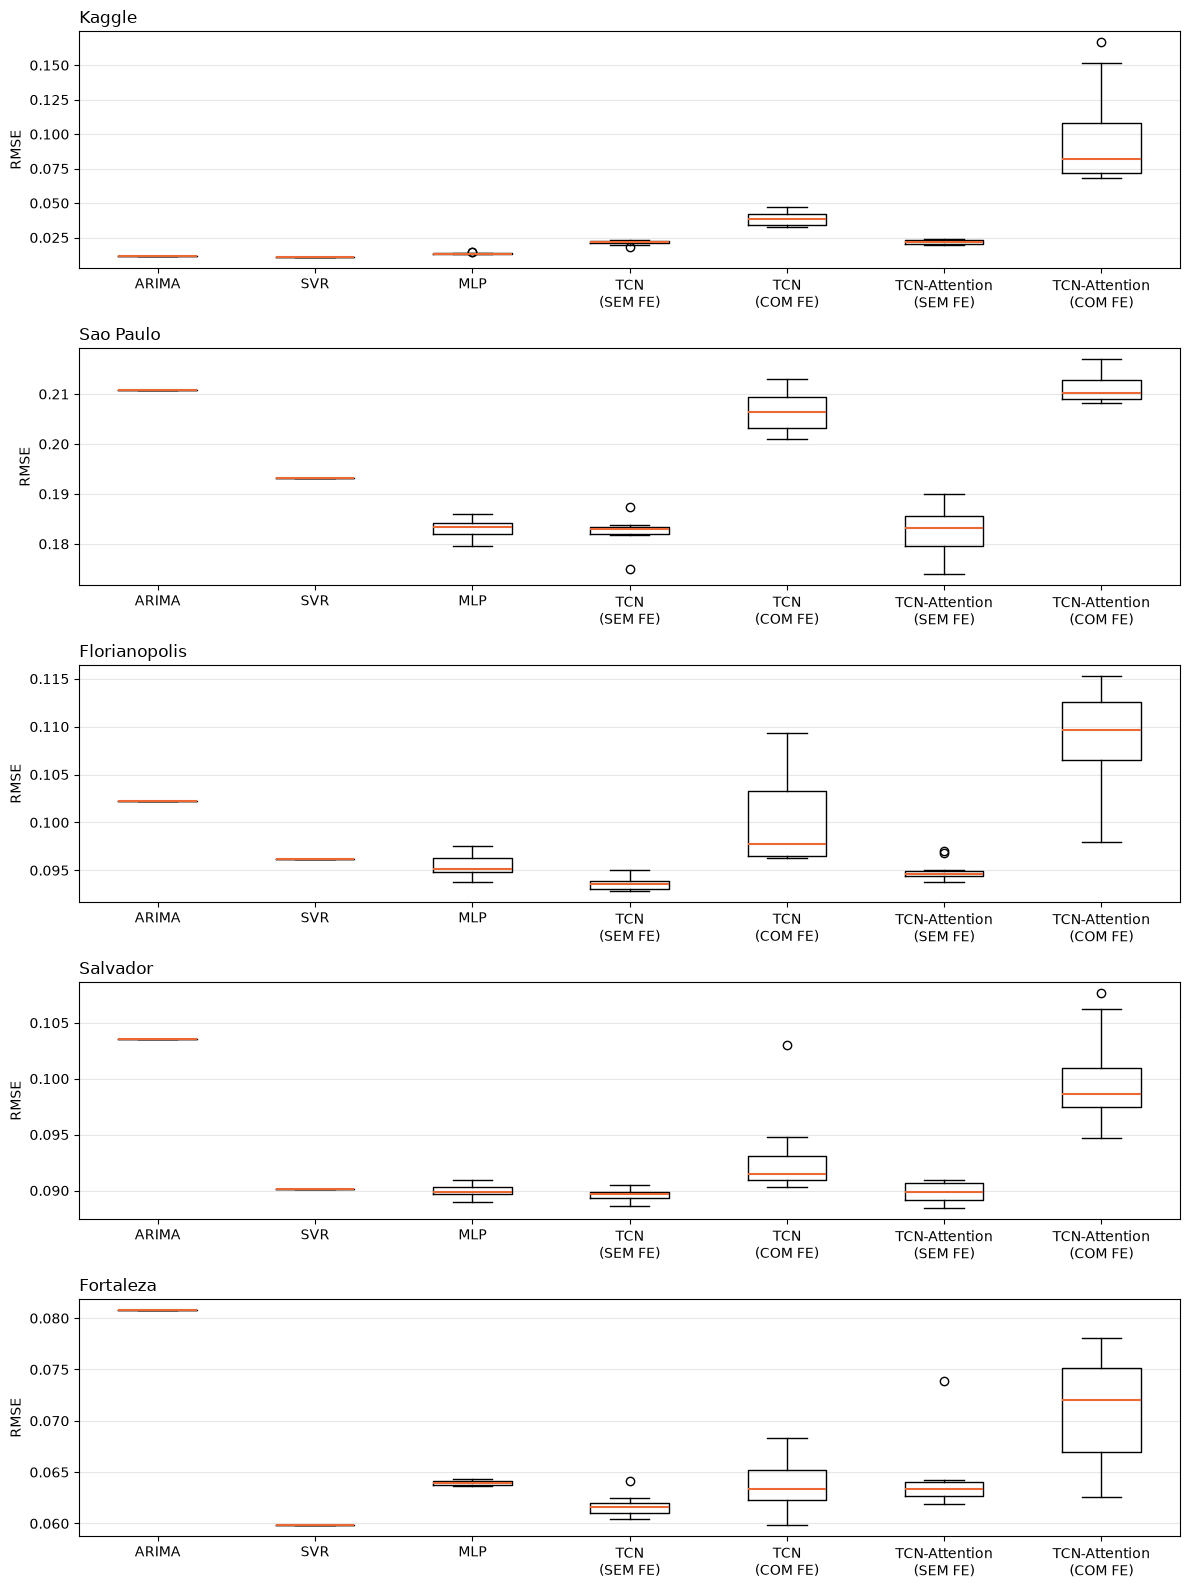

In [ ]:
fig, eixos = plt.subplots(len(DATASETS), 1, figsize=(12, 3.2 * len(DATASETS)))
for ax, nome in zip(eixos, DATASETS):
    g = RES[RES.dataset == nome]
    dados_box = [g[g.modelo_cond == m].RMSE.to_numpy() for m in ORDEM]
    ax.boxplot(dados_box, tick_labels=[m.replace(" (", "\n(") for m in ORDEM], widths=0.5,
               medianprops=dict(color="#eb6834", lw=1.5))
    ax.set_title(nome, loc="left"); ax.set_ylabel("RMSE"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(PASTA / "boxplot_rmse.png", dpi=150); plt.show()

## 8. Friedman–Nemenyi: diagrama de distância crítica ([MDPI] Fig. 8; Demšar, 2006)
- **Blocos:** os 5 datasets (N = 5). Este é o uso do teste previsto por Demšar: comparar métodos sobre vários conjuntos de dados.
- **Concorrentes:** os 7 modelos/condições, comparados pelo RMSE médio das 10 execuções.

Friedman χ² = 18.77, p = 0.00457 | Nemenyi CD = 4.03 (k = 7, N = 5)


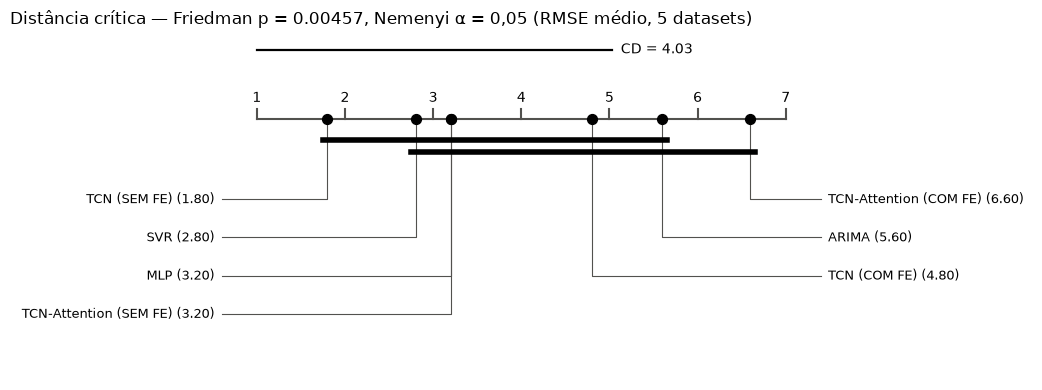

In [ ]:
Q_NEMENYI = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}   # α = 0,05
B = RES.groupby(["dataset", "modelo_cond"]).RMSE.mean().unstack()[ORDEM]
N, k = B.shape
postos = pd.Series(np.apply_along_axis(rankdata, 1, B.to_numpy()).mean(0), index=B.columns)
chi2, p = friedmanchisquare(*[B[c] for c in B.columns])
CD = Q_NEMENYI[k] * np.sqrt(k * (k + 1) / (6 * N))
print(f"Friedman χ² = {chi2:.2f}, p = {p:.3g} | Nemenyi CD = {CD:.2f} (k = {k}, N = {N})")

ordem = postos.sort_values().index.tolist()
grupos = []
for i, a in enumerate(ordem):
    j = max(jj for jj in range(i, k) if postos[ordem[jj]] - postos[a] < CD)
    if j > i and not any(gi <= i and j <= gj for gi, gj in grupos): grupos.append((i, j))
fig, ax = plt.subplots(figsize=(11, 4)); ax.set_xlim(-1.8, k + 2.8); ax.set_ylim(0, 1); ax.axis("off"); y0 = 0.75
ax.plot([1, k], [y0, y0], color="#52514e")
for t in range(1, k + 1):
    ax.plot([t, t], [y0, y0 + 0.03], color="#52514e"); ax.text(t, y0 + 0.05, str(t), ha="center")
ax.plot([1, 1 + CD], [0.95, 0.95], color="k", lw=1.6); ax.text(1 + CD + 0.1, 0.95, f"CD = {CD:.2f}", va="center")
for idx, c in enumerate(ordem):
    r = postos[c]; esq = idx < (k + 1) // 2
    yl = 0.52 - 0.11 * (idx if esq else k - 1 - idx); xl = 0.6 if esq else k + 0.4
    ax.plot([r, r, xl], [y0, yl, yl], color="#52514e", lw=0.8); ax.scatter([r], [y0], s=50, color="k", zorder=5)
    ax.text(xl + (-0.08 if esq else 0.08), yl, f"{c} ({r:.2f})", ha="right" if esq else "left", va="center", fontsize=9.5)
for gi, (i, j) in enumerate(grupos):
    ax.plot([postos[ordem[i]] - 0.05, postos[ordem[j]] + 0.05], [y0 - 0.06 - 0.035 * gi] * 2, color="k", lw=4)
ax.set_title(f"Distância crítica — Friedman p = {p:.3g}, Nemenyi α = 0,05 (RMSE médio, {N} datasets)", loc="left")
plt.tight_layout(); plt.savefig(PASTA / "distancia_critica.png", dpi=150); plt.show()

## 9. Real × TCN-Attention nos 150 primeiros pontos do teste ([MDPI] Figs. 9–12)
Para cada condição, mostramos a execução com o RMSE mediano, que é a mais representativa das 10.

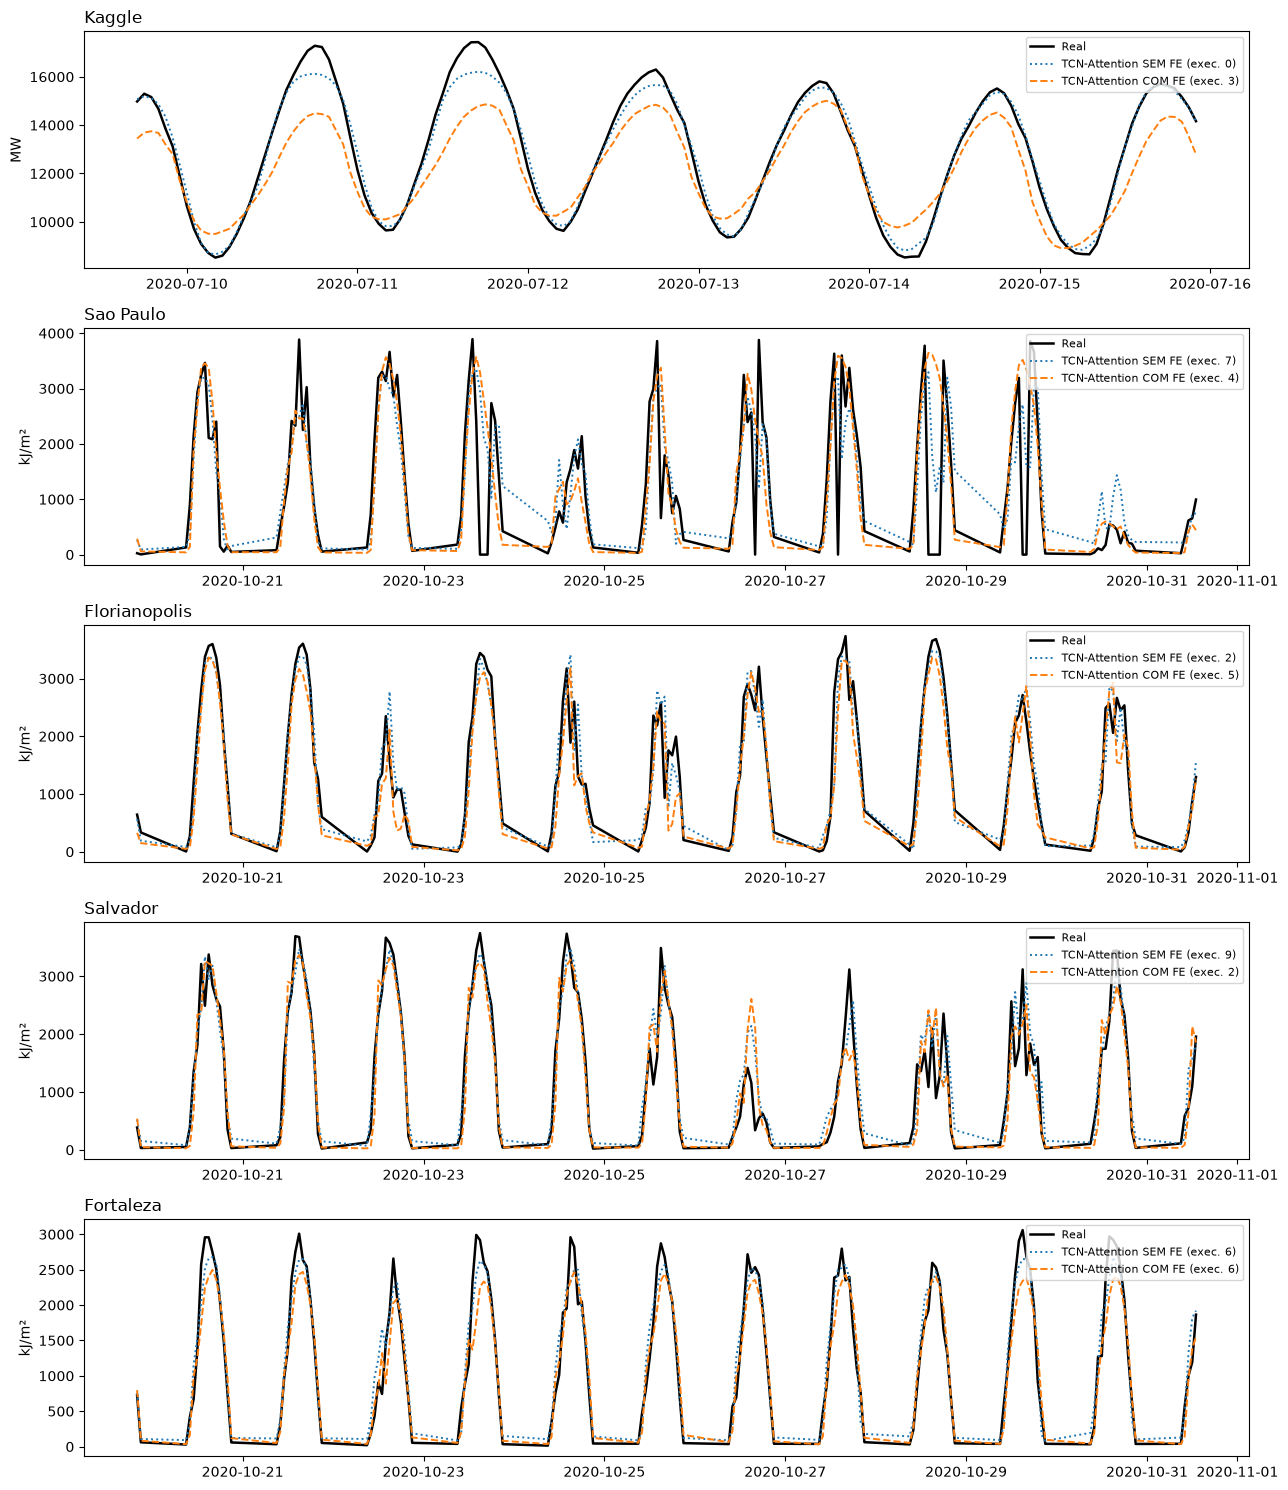

In [ ]:
fig, eixos = plt.subplots(len(DATASETS), 1, figsize=(13, 3 * len(DATASETS)))
for ax, nome in zip(eixos, DATASETS):
    d = DATASETS[nome]; real = d["serie"]["actual"].iloc[-d["n_te"]:]
    ax.plot(real.index[:150], real.to_numpy()[:150], color="k", lw=1.8, label="Real")
    for condicao, estilo in [("SEM", ":"), ("COM", "--")]:
        g = RES[(RES.dataset == nome) & (RES.modelo == "TCN-Attention") & (RES.condicao == condicao)].sort_values("RMSE")
        e = int(g.execucao.iloc[len(g) // 2])
        pred = np.load(PASTA / "previsoes" / f"{nome}__TCN-Attention__{condicao}__{e}.npy")
        ax.plot(real.index[:150], pred[:150], ls=estilo, lw=1.4, label=f"TCN-Attention {condicao} FE (exec. {e})")
    ax.set_title(nome, loc="left"); ax.set_ylabel("MW" if nome == "Kaggle" else "kJ/m²"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(PASTA / "forecast_tcn_attention.png", dpi=150); plt.show()